# Main question
Hiệu quả dự báo của model Dlinear thay đổi như thế nào khi số lượng historical cycles L/P thay đổi và số lượng future cycles T/P thay đổi?

Với:
- P = period
- L = look-back length
- T = forecast horizon

và:
- Historical context ratio = L/P
- Forecast ratio = T/P


In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (mean_squared_error, mean_absolute_error)

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

### Configuration

Ở experiment đầu tiên này, em sẽ cố đinh: P = 24


In [3]:
P = 24
context_ratios = [0.5, 1, 2, 4, 8]
forecast_ratios = [0.5, 1, 2, 4, 8]

In [4]:
for ratio in context_ratios:
    L = int(P * ratio)
    print(f"L/P {ratio:<3} => L = {L}")

L/P 0.5 => L = 12
L/P 1   => L = 24
L/P 2   => L = 48
L/P 4   => L = 96
L/P 8   => L = 192


In [5]:
for ratio in forecast_ratios:
    T = int(P * ratio)
    print(f"T/P {ratio:<3} => T = {T}")

T/P 0.5 => T = 12
T/P 1   => T = 24
T/P 2   => T = 48
T/P 4   => T = 96
T/P 8   => T = 192


In [ ]:
# seriess -> train/val/test -> window -> dataloader
def prepare_data(series, lookback, horizon, batch_size=32):
    n = len(series)

    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    train_series = series[:train_end]
    val_series = series[train_end:val_end]
    test_series = series[val_end:]

    X_train, y_train = create_windows(train_series, lookback, horizon)

    X_val, y_val = create_windows(val_series, lookback, horizon)

    X_test, y_test = create_windows(test_series, lookback, horizon)

    X_train = torch.tensor(X_train, dtype=torch.float32)

    y_train = torch.tensor(y_train, dtype=torch.float32)

    X_val = torch.tensor(X_val, dtype=torch.float32)

    y_val = torch.tensor(y_val, dtype=torch.float32)

    X_test = torch.tensor(X_test, dtype=torch.float32)

    y_test = torch.tensor(y_test, dtype=torch.float32)

    train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)

    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size, shuffle=False)

    test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, test_loader

In [10]:
# gom toàn bộ các bước chuẩn bị dữ liệu vào một hàm

def run_experiment(period, lookback, horizon, series_length=5000, kernel_size=5, epochs=50, learning_rate=1e-3, seed=42):
    set_seed(seed)

# tạo dữ liệu giả lập
    _, series, _, _, _ = generate_series(length=series_length, period=period, amplitude=1.0, trend_slope=0.0, noise_std=0.0, seed=seed)

# data pipeline
    train_loader, val_loader, test_loader = prepare_data(series=series, lookback=lookback, horizon=horizon, batch_size=32)

# Dlinear model
    model = DLinear(lookback=lookback, horizon=horizon, kernel_size=kernel_size)

# training
    train_losses, val_losses = train_model(model=model, train_loader=train_loader, val_loader=val_loader, epochs=epochs, learning_rate=learning_rate)

# đánh giá mô hình trên tập test
    mse, mae, predictions, targets = evaluate_model(model, test_loader)

    return {
        "P": period,
        "L": lookback,
        "T": horizon,

        "L/P": lookback / period,
        "T/P": horizon / period,

        "MSE": mse,
        "MAE": mae
    }

In [12]:
def generate_series(length=5000, period=24, amplitude=1.0, trend_slope=0.0, noise_std=0.0, phase=0.0, seed=42,):
    rng = np.random.default_rng(seed)

    t = np.arange(length)
    trend = trend_slope * t
    periodic = amplitude * np.sin(2 * np.pi * t / period + phase)

    noise = rng.normal(loc=0.0, scale=noise_std, size=length)

    series = trend + periodic + noise

    return t, series, trend, periodic, noise

In [15]:
required_objects = [
    "set_seed",
    "generate_series",
    "create_windows",
    "prepare_data",
    "MovingAverage",
    "DLinear",
    "train_one_epoch",
    "validate",
    "train_model",
    "evaluate_model"
]

for name in required_objects:
    if name in globals():
        print(f"{name:20s} v")
    else:
        print(f"{name:20s} x MISSING")

set_seed             v
generate_series      v
create_windows       x MISSING
prepare_data         v
MovingAverage        x MISSING
DLinear              x MISSING
train_one_epoch      x MISSING
validate             x MISSING
train_model          x MISSING
evaluate_model       x MISSING


In [16]:
def create_windows(
    series,
    lookback,
    horizon
):
    X = []
    y = []

    for i in range(
        len(series) - lookback - horizon + 1
    ):
        # historical window
        X.append(
            series[i:i + lookback]
        )

        # future target
        y.append(
            series[
                i + lookback:
                i + lookback + horizon
            ]
        )

    return np.array(X), np.array(y)

In [17]:
# test create_windows function

series = np.array([1, 2, 3, 4, 5, 6, 7, 8])

X_demo, y_demo = create_windows(
    series,
    lookback=3,
    horizon=2
)

print("X:")
print(X_demo)

print("\ny:")
print(y_demo)

X:
[[1 2 3]
 [2 3 4]
 [3 4 5]
 [4 5 6]]

y:
[[4 5]
 [5 6]
 [6 7]
 [7 8]]


In [18]:
class MovingAverage(nn.Module):

    def __init__(
        self,
        kernel_size
    ):
        super().__init__()

        self.kernel_size = kernel_size

        self.avg_pool = nn.AvgPool1d(
            kernel_size=kernel_size,
            stride=1
        )

    def forward(self, x):

        pad = (
            self.kernel_size - 1
        ) // 2

        # lặp lại giá trị đầu tiên
        front = x[:, :1].repeat(
            1,
            pad
        )

        # lặp lại giá trị cuối cùng
        end = x[:, -1:].repeat(
            1,
            pad
        )

        # padding
        x_padded = torch.cat(
            [
                front,
                x,
                end
            ],
            dim=1
        )

        # moving average
        trend = self.avg_pool(
            x_padded.unsqueeze(1)
        ).squeeze(1)

        return trend

In [19]:
# add Dlinear

class DLinear(nn.Module):

    def __init__(
        self,
        lookback,
        horizon,
        kernel_size=5
    ):
        super().__init__()

        # decomposition
        self.moving_avg = MovingAverage(
            kernel_size=kernel_size
        )

        # linear layer for trend
        self.linear_trend = nn.Linear(
            lookback,
            horizon
        )

        # linear layer for remainder
        self.linear_remainder = nn.Linear(
            lookback,
            horizon
        )

    def forward(self, x):

        trend = self.moving_avg(x)

        remainder = x - trend

        trend_output = self.linear_trend(
            trend
        )

        remainder_output = (
            self.linear_remainder(
                remainder
            )
        )

        output = (
            trend_output + remainder_output)

        return output

In [20]:
# add train_one_epoch

def train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer
):
    model.train()

    total_loss = 0.0

    for X_batch, y_batch in train_loader:

        # Reset gradient
        optimizer.zero_grad()

        # Forward
        y_pred = model(
            X_batch
        )

        # tính loss
        loss = criterion(
            y_pred,
            y_batch
        )

        # lan truyền ngược
        loss.backward()

        # cập nhật weights
        optimizer.step()

        # ước lượng loss
        total_loss += (
            loss.item()* X_batch.size(0)
        )

    average_loss = (
        total_loss / len(train_loader.dataset)
    )

    return average_loss

In [21]:
# add validate

def validate(
    model,
    val_loader,
    criterion
):
    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            # forward
            y_pred = model(
                X_batch
            )

            # tính loss
            loss = criterion(
                y_pred,
                y_batch
            )

            total_loss += (
                loss.item() * X_batch.size(0)
            )

    average_loss = (
        total_loss / len(val_loader.dataset)
    )

    return average_loss

In [ ]:
# add train model

def train_model(
    model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3
):
    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # train
        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        # đánh giá
        val_loss = validate(
            model,
            val_loader,
            criterion
        )

        # lưu losses
        train_losses.append(
            train_loss
        )

        val_losses.append(
            val_loss
        )

        # in ra thông tin
        if (
            epoch == 0 or (epoch + 1) % 10 == 0
        ):
            print(
                f"Epoch "
                f"{epoch + 1:3d}/{epochs} | "
                f"Train MSE: "
                f"{train_loss:.6f} | "
                f"Val MSE: "
                f"{val_loss:.6f}"
            )

    return (
        train_losses,
        val_losses
    )

In [23]:
 # add evaluate model

 def evaluate_model(model, data_loader):
    model.eval()

    predictions = []
    targets = []

    with torch.no_grad():

        for X_batch, y_batch in data_loader:

            y_pred = model(
                X_batch
            )

            predictions.append(
                y_pred.cpu().numpy()
            )

            targets.append(
                y_batch.cpu().numpy()
            )

    predictions = np.concatenate(
        predictions,
        axis=0
    )

    targets = np.concatenate(
        targets,
        axis=0
    )

    mse = mean_squared_error(
        targets.flatten(),
        predictions.flatten()
    )

    mae = mean_absolute_error(
        targets.flatten(),
        predictions.flatten()
    )

    return (
        mse,
        mae,
        predictions,
        targets
    )

In [ ]:
# check if all required objects are defined
required_objects = [
    "set_seed",
    "generate_series",
    "create_windows",
    "prepare_data",
    "MovingAverage",
    "DLinear",
    "train_one_epoch",
    "validate",
    "train_model",
    "evaluate_model"
]

for name in required_objects:
    if name in globals():
        print(f"{name:20s} v")
    else:
        print(f"{name:20s} x MISSING")

set_seed             v
generate_series      v
create_windows       v
prepare_data         v
MovingAverage        v
DLinear              v
train_one_epoch      v
validate             v
train_model          v
evaluate_model       v


In [25]:
test_result = run_experiment(
    period=24,
    lookback=96,
    horizon=24,
    epochs=50,
    seed=42
)

test_result

Epoch   1/50 | Train MSE: 0.052109 | Val MSE: 0.000097
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000002


{'P': 24,
 'L': 96,
 'T': 24,
 'L/P': 4.0,
 'T/P': 1.0,
 'MSE': 2.2733618152415147e-06,
 'MAE': 0.0004675605450756848}

Trước khi đi vào chạy dry-run grid, vì nếu chạy full stress mao có kích thước 5 x 5 thì việc cấu hình sẽ mất khá nhiều thời gian
mà khi đó em cũng đang muốn thử việc xác nhận xem pipeline hoạt động có ổn không (việc hàm run_ex có hoạt động trơn tru qua nhiều lần gọi không,
khởi tạo mô hình, truyền tham số l/p va t/p ok không, thu nhập và ghi lại kết quả có gặp vấn đề gì không)
=> chạy test 1 grid nhỏ

In [27]:
epochs = 5
P = 24

test_context_ratios = [1, 2]
test_forecast_ratios = [1, 2]

In [29]:
test_results = []

for context_ratio in test_context_ratios:

    for forecast_ratio in test_forecast_ratios:

        L = int(P * context_ratio)
        T = int(P * forecast_ratio)

        result = run_experiment(
            period=P,
            lookback=L,
            horizon=T,
            epochs=5,
            seed=42
        )

        test_results.append(result)

pd.DataFrame(test_results)

Epoch   1/5 | Train MSE: 0.247615 | Val MSE: 0.022930
Epoch   1/5 | Train MSE: 0.237449 | Val MSE: 0.023908
Epoch   1/5 | Train MSE: 0.108150 | Val MSE: 0.000221
Epoch   1/5 | Train MSE: 0.120894 | Val MSE: 0.000673


,P,L,T,L/P,T/P,MSE,MAE
0,24,24,24,1.0,1.0,1.709156e-09,1.181155e-05
1,24,24,48,1.0,2.0,1.225000e-07,8.691967e-05
2,24,48,24,2.0,1.0,6.462249e-15,6.028722e-08
3,24,48,48,2.0,2.0,7.037480e-15,6.071863e-08


In [30]:
# tress grid

results = []

for context_ratio in context_ratios:

    for forecast_ratio in forecast_ratios:

        L = int(P * context_ratio)
        T = int(P * forecast_ratio)

        print(
            f"\nRunning: "
            f"L/P={context_ratio},"
            f"T/P={forecast_ratio}"
        )

        result = run_experiment(
            period=P,
            lookback=L,
            horizon=T,
            epochs=50,
            seed=42
        )

        results.append(result)



Running: L/P=0.5,T/P=0.5
Epoch   1/50 | Train MSE: 0.299628 | Val MSE: 0.114872
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000000

Running: L/P=0.5,T/P=1
Epoch   1/50 | Train MSE: 0.298425 | Val MSE: 0.108017
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000000

Running: L/P=0.5,T/P=2
Epoch   1/50 | Train MSE: 0.310242 | Val MSE: 0.116075
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 

In [31]:
results_df = pd.DataFrame(results)
results_df

,P,L,T,L/P,T/P,MSE,MAE
0,24,12,12,0.5,0.5,2.331023e-15,3.399285e-08
1,24,12,24,0.5,1.0,2.509576e-15,3.498322e-08
2,24,12,48,0.5,2.0,2.480346e-15,3.398893e-08
3,24,12,96,0.5,4.0,2.811917e-15,3.641665e-08
4,24,12,192,0.5,8.0,2.892485e-15,3.647322e-08
5,24,24,12,1.0,0.5,1.987962e-15,2.942936e-08
6,24,24,24,1.0,1.0,3.224750e-15,4.051030e-08
7,24,24,48,1.0,2.0,3.191550e-15,4.058042e-08
8,24,24,96,1.0,4.0,3.049185e-15,3.849152e-08
9,24,24,192,1.0,8.0,3.656421e-15,4.268630e-08


In [ ]:
results_df.to_csv("../results/dlinear_stress_results.csv", index=False)

In [34]:
# đưa bảng kết quả đó thành matrix

stress_map = results_df.pivot(
    index="L/P",
    columns="T/P",
    values="MSE"
)

stress_map

T/P,0.5,1.0,2.0,4.0,8.0
L/P,,,,,
0.5,2.331023e-15,2.509576e-15,2.480346e-15,2.811917e-15,2.892485e-15
1.0,1.987962e-15,3.224750e-15,3.191550e-15,3.049185e-15,3.656421e-15
2.0,8.526929e-15,5.181682e-10,8.037017e-15,1.080294e-13,1.312504e-10
4.0,3.293362e-10,2.273362e-06,1.024585e-07,4.291846e-07,6.514739e-07
8.0,8.450127e-07,7.547655e-06,1.900884e-05,4.347482e-06,1.828202e-05


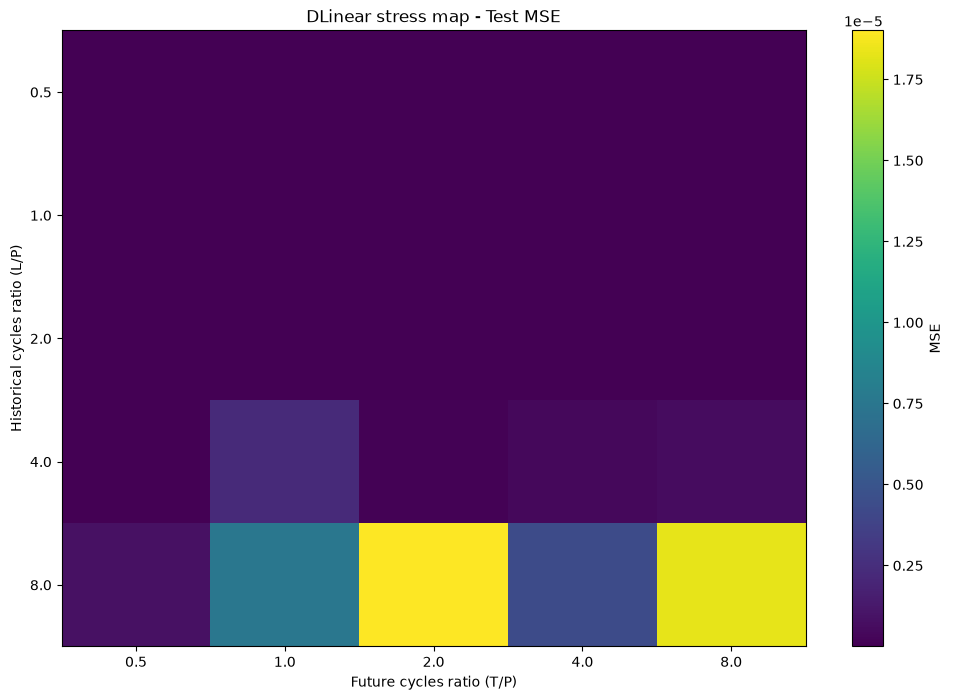

In [36]:
fig, ax = plt.subplots(figsize=(12, 8))

image = ax.imshow(
    stress_map.values,
    aspect="auto"
)

ax.set_xticks(range(len(stress_map.columns)))

ax.set_xticklabels(stress_map.columns)

ax.set_yticks(range(len(stress_map.index)))

ax.set_yticklabels(stress_map.index)

ax.set_xlabel("Future cycles ratio (T/P)")

ax.set_ylabel("Historical cycles ratio (L/P)")

ax.set_title("DLinear stress map - Test MSE")

plt.colorbar(image, ax=ax, label="MSE")

plt.show()

**Nhận xét:**
- Dlinear học chuỗi giả lập này tốt ở hầu hết các cấu hình vì thang đo MSE nằm ở ngưỡng 0.0 đến 0.000018
- khi L/P < 2.0 model đạt MSE thấp kể cả dự báo T/P dài hay ngắn => lí do vì với 1 sóng sin chuẩn thì chỉ cần 0.5 - 2 chu kì thôi là các lớp linear đã đủ khớp chính xác dạng sóng mà k bị nhiễu bởi các tham số khác - "https://arxiv.org/abs/2304.08424"
- khi L/P lớn hơn thì MSE bắt đầu tăng rõ ở các mốc như T/P = 2 và 8 => lí do vì khi cửa sổ lookback dài quá dẫn đến ma trận weights của lớp linear lớn theo -> khiến model có thể bị quá tải dữ liệu thừa như overfit vào nhiễu hoặc mất đi tính linh hoạt - "https://arxiv.org/abs/2205.13504"

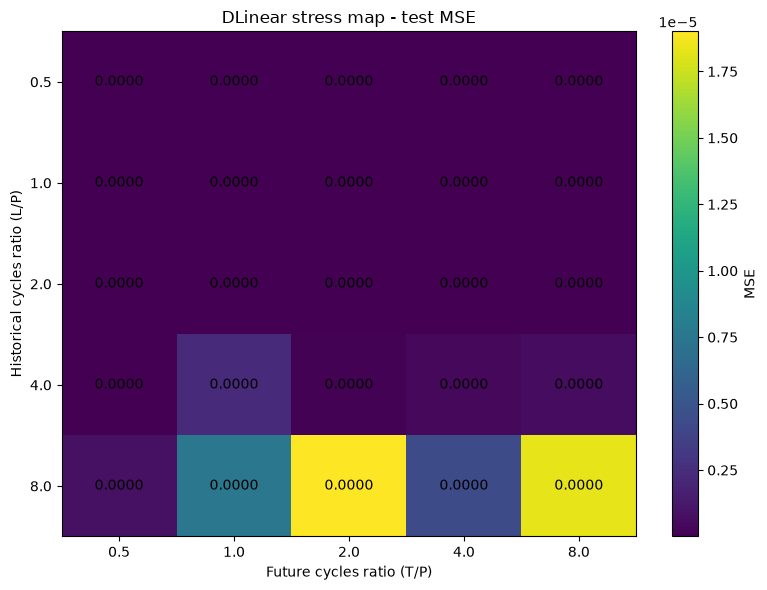

In [37]:
fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    stress_map.values,
    aspect="auto"
)

ax.set_xticks(
    range(len(stress_map.columns))
)

ax.set_xticklabels(
    stress_map.columns
)

ax.set_yticks(
    range(len(stress_map.index))
)

ax.set_yticklabels(
    stress_map.index
)

for i in range(len(stress_map.index)):
    for j in range(len(stress_map.columns)):

        value = stress_map.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.4f}",
            ha="center",
            va="center"
        )

ax.set_xlabel("Future cycles ratio (T/P)")
ax.set_ylabel("Historical cycles ratio (L/P)")

ax.set_title("DLinear stress map - test MSE")

plt.colorbar(image, ax=ax, label="MSE")

plt.tight_layout()
plt.show()

**Nhận xét:**
Nhìn vào Stress map thì em có thể đánh giá sơ bộ như:
- nếu quan sát vào dòng L/P = 2.0 "Khi model chỉ nhìn 2 historical cycles (L/P = 2) nhưng phải forecast ngày càng xa (T/P = 0.5 - 8.0) thì error sẽ thay đổi thế nào?" => tất cả các giá trị T/P đều sấp xỉ bằng nhau error hầu như không suy giảm
- nếu quan sát vào cột T/P = 4.0 "Giữ nguyên độ dài của bước dự báo (T/P = 4), nếu cho model thêm historical cycles (L/P = 0.5 - 8.0) thì performance có cải thiện không?" => performance không cải thiện mà còn tệ dần đi.

=> Tuy nhiên em chưa kết luận được gì từ stress map này bởi nó đang có
- P = 24
- noise = 0
- trend = 0
- seed = 42

"tất cả mọi thứ đang được kiểm soát nên trong bộ dữ liệu được kiểm soát này thì performance thay đổi theo L/P hoặc T/P thôi ạ"

Ngoài ra, trong Dlinear Decomposition là Trend đi với độ rộng cửa số kernel size (quyết định xem bộ lọc sẽ triệt tiêu được bao nhiêu phần dao động). Để trích xuất đúng trend hoặc làm phẳng sóng sin thì độ rộng của cửa sổ kernel thường là **bội số** của chu kì P - "https://www.math.unm.edu/~lil/Stat581/STL.pdf"

Và nếu với 1 bộ dataset mới hoàn toàn và vẫn giữ k = 5 như em đang test với bộ dữ liệu giả lập, ví dụ P = 12, 24, 48, ... mà k = 5 thì k/P sẽ liên tục thay đổi => sự thay đổi MSE, khi đó chưa chắc đã do model giỏi hay dở mà có thể do k = 5 vô tình hợp với chu kì này nhưng lệch với chu kì khác.


In [38]:
plt.savefig(
    "../results/dlinear_stress_map.png",
    dpi=300,
    bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [50]:
# vì ở em đã cố định model = Dlinear và flow của nó sẽ là configuration -> Dlinear -> results thì điều này sẽ gây khó khăn trong việc dùng cùng 1 pipeline để so sánh model

def run_experiment(
    model_name,
    period,
    lookback,
    horizon,
    series_length=5000,
    kernel_size=5,
    epochs=50,
    learning_rate=1e-3,
    seed=42
):
    set_seed(seed)

    # tạo dữ liệu giả lập
    _, series, _, _, _ = generate_series(
        length=series_length,
        period=period,
        amplitude=1.0,
        trend_slope=0.0,
        noise_std=0.0,
        seed=seed
    )

    # data pipeline
    train_loader, val_loader, test_loader = prepare_data(
        series=series,
        lookback=lookback,
        horizon=horizon,
        batch_size=32
    )

    # lựa chọn model dựa trên model_name
    if model_name == "Linear":
        model = Linear(
            lookback=lookback,
            horizon=horizon
        )

    elif model_name == "DLinear":
        model = DLinear(
            lookback=lookback,
            horizon=horizon,
            kernel_size=kernel_size
        )

    elif model_name == "NLinear":
        model = NLinear(
            lookback=lookback,
            horizon=horizon
        )

    else:
        raise ValueError(
            f"Unknown model: {model_name}"
        )

    # huấn luyện
    train_losses, val_losses = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=epochs,
        learning_rate=learning_rate
    )

    # đánh giá
    mse, mae, predictions, targets = evaluate_model(
        model,
        test_loader
    )

    return {
        "Model": model_name,
        "P": period,
        "L": lookback,
        "T": horizon,
        "L/P": lookback / period,
        "T/P": horizon / period,
        "MSE": mse,
        "MAE": mae,
        "Seed": seed
    }

em sử dụng cấu trúc rẽ nhánh if else cho việc lựa chọn nhiều model trong 1 pipeline

=> như vậy thì tất cả các function khác đều giống nhau và chỉ khác ở model được lựa chọn

In [43]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from utils import (
    set_seed,
    generate_series,
    create_windows,
    Linear,
    MovingAverage,
    DLinear,
    NLinear,
    train_one_epoch,
    validate,
    train_model,
    evaluate_model
)

In [52]:
models = ["Linear", "DLinear", "NLinear"]

comparison_test = []

for model_name in models:

    print(
        f"\n===== {model_name} ====="
    )

    result = run_experiment(
        model_name=model_name,
        period=24,
        lookback=96,
        horizon=24,
        epochs=10,
        seed=42
    )

    comparison_test.append(
        result
    )


===== Linear =====
Epoch   1/10 | Train MSE: 0.054048 | Val MSE: 0.000129
Epoch  10/10 | Train MSE: 0.000000 | Val MSE: 0.000000

===== DLinear =====
Epoch   1/10 | Train MSE: 0.052365 | Val MSE: 0.000154
Epoch  10/10 | Train MSE: 0.000000 | Val MSE: 0.000000

===== NLinear =====
Epoch   1/10 | Train MSE: 0.100405 | Val MSE: 0.000277
Epoch  10/10 | Train MSE: 0.000000 | Val MSE: 0.000000


In [53]:
comparison_test_df = pd.DataFrame(comparison_test)

comparison_test_df

,Model,P,L,T,L/P,T/P,MSE,MAE,Seed
0,Linear,24,96,24,4.0,1.0,1.077498e-09,0.000026,42
1,DLinear,24,96,24,4.0,1.0,1.181235e-09,0.000027,42
2,NLinear,24,96,24,4.0,1.0,1.508031e-09,0.000030,42


In [54]:
# em sẽ chọn ra 5 configuration có ý nghĩa một cách cụ thể
selected_configs = [
    (1.0, 1.0), # ít history và forecast cũng ngắn
    (4.0, 1.0), # nhiều history nhưng forecast ngắn
    (1.0, 4.0), # ít history nhưng forecast dài
    (4.0, 4.0), # nhiều history và forecast dài
    (0.5, 8.0) # stress case mạnh vì timesteps nửa chu kì nhưng phải forecast T = 8*P = 192 timesteps ~ 8 chu kì
]

selected_configs

[(1.0, 1.0), (4.0, 1.0), (1.0, 4.0), (4.0, 4.0), (0.5, 8.0)]

In [56]:
P = 24
for context_ratio, forecast_ratio in selected_configs:

    L = int(P * context_ratio)
    T = int(P * forecast_ratio)

    print(
        f"L/P={context_ratio:<4}| "
        f"T/P={forecast_ratio:<4}| "
        f"L={L:<4} | "
        f"T={T:<4}"
    )

L/P=1.0 | T/P=1.0 | L=24   | T=24  
L/P=4.0 | T/P=1.0 | L=96   | T=24  
L/P=1.0 | T/P=4.0 | L=24   | T=96  
L/P=4.0 | T/P=4.0 | L=96   | T=96  
L/P=0.5 | T/P=8.0 | L=12   | T=192 


In [57]:
models = ["Linear", "DLinear", "NLinear"]

comparison_results = []

for context_ratio, forecast_ratio in selected_configs:

    L = int(P * context_ratio)
    T = int(P * forecast_ratio)

    print("\n" + "=" * 60)

    print(
        f"Configuration: "
        f"L/P={context_ratio}, "
        f"T/P={forecast_ratio}"
    )

    print(
        f"L={L}, T={T}"
    )

    print("=" * 60)

    for model_name in models:

        print(
            f"\n--- {model_name} ---"
        )

        result = run_experiment(
            model_name=model_name,
            period=P,
            lookback=L,
            horizon=T,
            epochs=50,
            seed=42
        )

        comparison_results.append(result)


Configuration: L/P=1.0, T/P=1.0
L=24, T=24

--- Linear ---
Epoch   1/50 | Train MSE: 0.259774 | Val MSE: 0.027776
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000000

--- DLinear ---
Epoch   1/50 | Train MSE: 0.210502 | Val MSE: 0.018419
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000000

--- NLinear ---
Epoch   1/50 | Train MSE: 0.700704 | Val MSE: 0.139695
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 

In [58]:
comparison_df = pd.DataFrame(comparison_results)

comparison_df

,Model,P,L,T,L/P,T/P,MSE,MAE,Seed
0,Linear,24,24,24,1.0,1.0,1.146610e-09,0.000026,42
1,DLinear,24,24,24,1.0,1.0,1.223187e-09,0.000027,42
2,NLinear,24,24,24,1.0,1.0,1.491041e-09,0.000030,42
3,Linear,24,96,24,4.0,1.0,3.025747e-07,0.000187,42
4,DLinear,24,96,24,4.0,1.0,2.699369e-06,0.000404,42
5,NLinear,24,96,24,4.0,1.0,7.741189e-07,0.000282,42
6,Linear,24,24,96,1.0,4.0,1.265117e-09,0.000027,42
7,DLinear,24,24,96,1.0,4.0,1.319973e-09,0.000028,42
8,NLinear,24,24,96,1.0,4.0,1.859282e-09,0.000033,42
9,Linear,24,96,96,4.0,4.0,1.090454e-06,0.000246,42


In [59]:
comparison_df[["Model", "L/P", "T/P", "MSE", "MAE"]]

,Model,L/P,T/P,MSE,MAE
0,Linear,1.0,1.0,1.146610e-09,0.000026
1,DLinear,1.0,1.0,1.223187e-09,0.000027
2,NLinear,1.0,1.0,1.491041e-09,0.000030
3,Linear,4.0,1.0,3.025747e-07,0.000187
4,DLinear,4.0,1.0,2.699369e-06,0.000404
5,NLinear,4.0,1.0,7.741189e-07,0.000282
6,Linear,1.0,4.0,1.265117e-09,0.000027
7,DLinear,1.0,4.0,1.319973e-09,0.000028
8,NLinear,1.0,4.0,1.859282e-09,0.000033
9,Linear,4.0,4.0,1.090454e-06,0.000246


In [60]:
mse_table = comparison_df.pivot_table(
    index=["L/P", "T/P"],
    columns="Model",
    values="MSE"
)

mse_table

Model         DLinear        Linear       NLinear
L/P T/P                                          
0.5 8.0  1.340517e-09  1.323014e-09  3.016398e-09
1.0 1.0  1.223187e-09  1.146610e-09  1.491041e-09
    4.0  1.319973e-09  1.265117e-09  1.859282e-09
4.0 1.0  2.699369e-06  3.025747e-07  7.741189e-07
    4.0  4.429892e-06  1.090454e-06  8.394103e-06

In [61]:
mae_table = comparison_df.pivot_table(
    index=["L/P", "T/P"],
    columns="Model",
    values="MAE"
)

mae_table

Model     DLinear    Linear   NLinear
L/P T/P                              
0.5 8.0  0.000028  0.000028  0.000041
1.0 1.0  0.000027  0.000026  0.000030
    4.0  0.000028  0.000027  0.000033
4.0 1.0  0.000404  0.000187  0.000282
    4.0  0.000522  0.000246  0.000716

Ở đây em định nghĩa:

$$Gain = \frac{MSE_{Linear} - MSE_{DLinear}}{MSE_{Linear}} \times 100$$

để gíup so sánh chuẩn hoá bởi nếu chỉ nhìn sao giá trị tuyệt đối như MSE của linear = 0.02 và MSE của Dlinear = 0.015 chẳng hạn thì số chênh lệch đang là 0.005
khi đổi sang Gain = 25% thì khi đó em có thể nói rõ rằng thành phần tách chuỗi giúp Dlinear giảm tới 25% sai số so với Linear.

Và với con số như thế em cũng có thể tự tin trả lời câu hỏi việc decomposition hiệu quả hơn Linear không + tạo ra map để xem múc độ đóng góp của decomposition

- "https://arxiv.org/abs/2205.13504"


In [62]:
mse_table["DLinear_Gain_%"] = ((mse_table["Linear"] - mse_table["DLinear"]) / mse_table["Linear"]) * 100

mse_table

Model         DLinear        Linear       NLinear  DLinear_Gain_%
L/P T/P                                                          
0.5 8.0  1.340517e-09  1.323014e-09  3.016398e-09       -1.322922
1.0 1.0  1.223187e-09  1.146610e-09  1.491041e-09       -6.678536
    4.0  1.319973e-09  1.265117e-09  1.859282e-09       -4.335989
4.0 1.0  2.699369e-06  3.025747e-07  7.741189e-07     -792.133272
    4.0  4.429892e-06  1.090454e-06  8.394103e-06     -306.242917

ở đây em thấy toàn bộ mang dấu -, mang hàm nghĩa là Dlinear không những không được cải thiện mà còn có sai số MSE cao hơn Linear trên tất cả các cấu hình thử nghiệm

Thật ra em nghĩ lí do ở đây là dữ liệu đang dùng là dữ liệu giả lập đang quá sạch, nó có sóng điều hoà đơn giản và k có xu hướng phức tạp hay biến động mùa vụ bị dịch chuyển gì => chỉ cần 1 lớp linear đơn giản là học được mà k cần tách chuỗi

In [63]:
model_columns = [
    "Linear",
    "DLinear",
    "NLinear"
]

mse_table["Best_Model"] = (mse_table[model_columns].idxmin(axis=1))

mse_table

Model         DLinear        Linear       NLinear  DLinear_Gain_% Best_Model
L/P T/P                                                                     
0.5 8.0  1.340517e-09  1.323014e-09  3.016398e-09       -1.322922     Linear
1.0 1.0  1.223187e-09  1.146610e-09  1.491041e-09       -6.678536     Linear
    4.0  1.319973e-09  1.265117e-09  1.859282e-09       -4.335989     Linear
4.0 1.0  2.699369e-06  3.025747e-07  7.741189e-07     -792.133272     Linear
    4.0  4.429892e-06  1.090454e-06  8.394103e-06     -306.242917     Linear

In [64]:
comparison_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

mse_table.to_csv("../results/model_comparison_mse.csv")

In [65]:
# vẽ biểu đồ để so sánh

plot_df = comparison_df.copy()

plot_df["Configuration"] = ("L/P=" + plot_df["L/P"].astype(str) + ", T/P=" + plot_df["T/P"].astype(str))

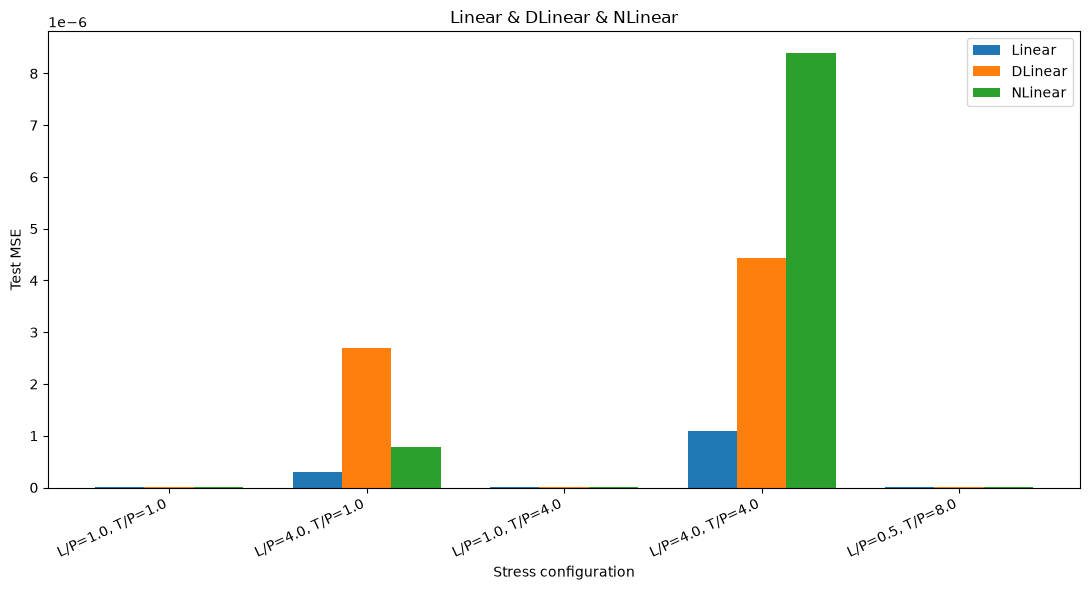

In [66]:
configurations = (plot_df["Configuration"].drop_duplicates().tolist())

x = np.arange(
    len(configurations)
)

width = 0.25

fig, ax = plt.subplots(
    figsize=(11, 6)
)

for i, model_name in enumerate(models):

    model_data = (
        plot_df[
            plot_df["Model"] == model_name
        ]
        .set_index("Configuration")
        .loc[configurations]
    )

    ax.bar(
        x + (i - 1) * width,
        model_data["MSE"],
        width,
        label=model_name
    )

ax.set_xticks(x)

ax.set_xticklabels(
    configurations,
    rotation=25,
    ha="right"
)

ax.set_ylabel("Test MSE")
ax.set_xlabel("Stress configuration")
ax.set_title("Linear & DLinear & NLinear")
ax.legend()

plt.tight_layout()
plt.show()

Trên chuỗi thời gian giả lập sạch như thế này thì các biến thể của Linear là Dlinear và Nlinear không mang lại nhiều lợi ích mà còn gia tăng sai số khi mở rộng L/P >= 4.0

In [68]:
gain_df = (mse_table.reset_index())

gain_df["Configuration"] = ("L/P=" + gain_df["L/P"].astype(str) + ", T/P=" + gain_df["T/P"].astype(str))


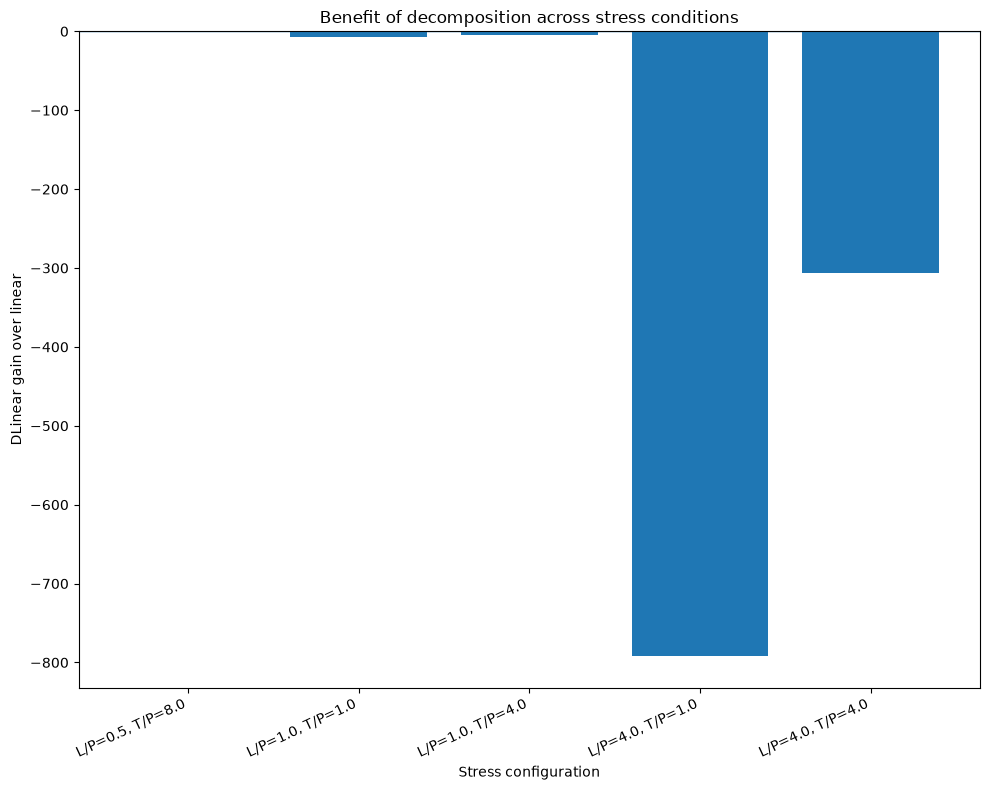

In [69]:
fig, ax = plt.subplots(figsize=(10, 8))

ax.bar(
    gain_df["Configuration"],
    gain_df["DLinear_Gain_%"]
)

ax.axhline(0, linewidth=1)

ax.set_xlabel("Stress configuration")

ax.set_ylabel("DLinear gain over linear")

ax.set_title("Benefit of decomposition across stress conditions")

plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

Gain < 0 => linear tốt hơn Dlinear với bộ dữ liệu giả lập

Ở trên em đang dừng dữ liệu giả lập đơn giản, chu kì sóng sẽ lặp đi lặp lại xt = st
Ở bước tiếp theo, em sẽ thử thách mô hình bằng cách thêm yếu tố mới vào dữ liệu (trend hình thành bởi kt với k là mức độ tăng trưởng và t là mốc thời gian)

=> em muốn xem thử với việc thêm xu hướng tăng hoặc giảm ngày càng mạnh thì liệu decomposition của Dlinear có giúp nó tốt hơn so với linear và Nlinear không?

In [70]:
# sửa function để có thể nhận thêm trend slope và noise_std

def run_experiment(
    model_name,
    period,
    lookback,
    horizon,
    series_length=5000,
    amplitude=1.0,
    trend_slope=0.0,
    noise_std=0.0,
    kernel_size=5,
    epochs=50,
    learning_rate=1e-3,
    seed=42
):
    set_seed(seed)

    _, series, _, _, _ = generate_series(
        length=series_length,
        period=period,
        amplitude=amplitude,
        trend_slope=trend_slope,
        noise_std=noise_std,
        seed=seed
    )

    train_loader, val_loader, test_loader = prepare_data(
        series=series,
        lookback=lookback,
        horizon=horizon,
        batch_size=32
    )

    if model_name == "Linear":

        model = Linear(
            lookback=lookback,
            horizon=horizon
        )

    elif model_name == "DLinear":

        model = DLinear(
            lookback=lookback,
            horizon=horizon,
            kernel_size=kernel_size
        )

    elif model_name == "NLinear":

        model = NLinear(
            lookback=lookback,
            horizon=horizon
        )

    else:

        raise ValueError(f"Unknown model: {model_name}")

    train_losses, val_losses = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=epochs,
        learning_rate=learning_rate
    )

    mse, mae, predictions, targets = evaluate_model(
        model=model,
        test_loader=test_loader
    )

    return {
        "Model": model_name,
        "P": period,
        "L": lookback,
        "T": horizon,
        "L/P": lookback / period,
        "T/P": horizon / period,
        "Trend": trend_slope,
        "Noise": noise_std,
        "MSE": mse,
        "MAE": mae,
        "Seed": seed
    }

In [71]:
# test nhanh function
test_result = run_experiment(
    model_name="DLinear",
    period=24,
    lookback=96,
    horizon=24,
    trend_slope=0.001,
    noise_std=0.0,
    epochs=10,
    seed=42
)

test_result

Epoch   1/10 | Train MSE: 0.614886 | Val MSE: 0.016089
Epoch  10/10 | Train MSE: 0.000030 | Val MSE: 0.000064


{'Model': 'DLinear',
 'P': 24,
 'L': 96,
 'T': 24,
 'L/P': 4.0,
 'T/P': 1.0,
 'Trend': 0.001,
 'Noise': 0.0,
 'MSE': 0.00013021087215747684,
 'MAE': 0.005956663750112057,
 'Seed': 42}

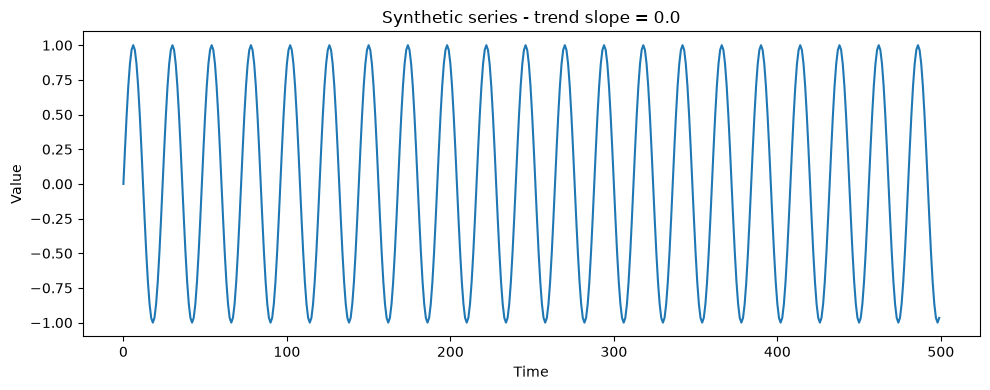

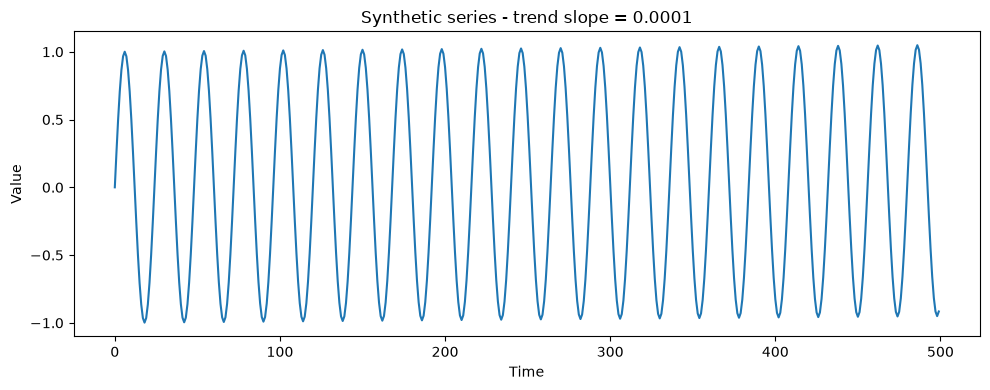

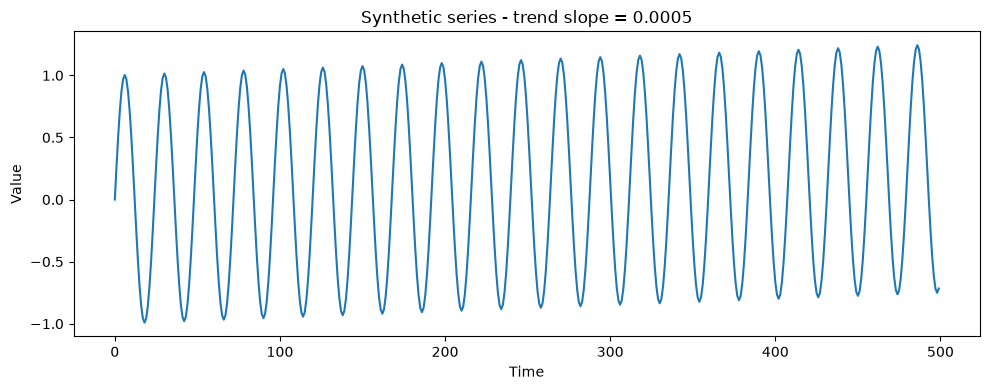

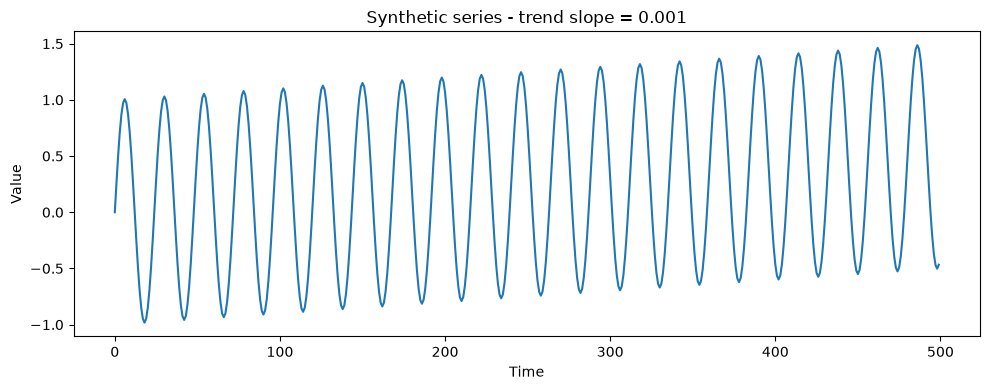

In [72]:
trend_levels = [0.0, 0.0001, 0.0005, 0.001] 
# vì ở đây length = 5000 từ 0 - 4999, thành phần xu hướng = k x t
# nếu k = 0.001 tới cuối chuỗi t = 4999, giá trị xu hướng sẽ tăng lên tới 0.001 x 4999 ~ 5
# tăng xu hướng lên thành 5 ở cuối chuỗi đồng nghĩa với giá trị xu hướng đã cao hơn 5 lần so với biên độ sóng ban đầu A = 1

for trend_slope in trend_levels:

    t, series, trend, periodic, noise = generate_series(
        length=500,
        period=24,
        amplitude=1.0,
        trend_slope=trend_slope,
        noise_std=0.0,
        seed=42
    )

    plt.figure(figsize=(10, 4))

    plt.plot(t, series)

    plt.title(f"Synthetic series - trend slope = {trend_slope}")

    plt.xlabel("Time")

    plt.ylabel("Value")

    plt.tight_layout()
    plt.show()

In [73]:
trend_test_config = {"period": 24, "lookback": 96, "horizon": 96}

trend_results = []

models = [
    "Linear",
    "DLinear",
    "NLinear"
]

for trend_slope in trend_levels:

    print("\n" + "=" * 60)
    print(
        f"Trend slope = {trend_slope}"
    )
    print("=" * 60)

    for model_name in models:

        print(
            f"\n--- {model_name} ---"
        )

        result = run_experiment(
            model_name=model_name,
            period=24,
            lookback=96,
            horizon=96,
            trend_slope=trend_slope,
            noise_std=0.0,
            epochs=50,
            seed=42
        )

        trend_results.append(
            result
        )



Trend slope = 0.0

--- Linear ---
Epoch   1/50 | Train MSE: 0.054465 | Val MSE: 0.000186
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000001

--- DLinear ---
Epoch   1/50 | Train MSE: 0.047143 | Val MSE: 0.000112
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000001 | Val MSE: 0.000004

--- NLinear ---
Epoch   1/50 | Train MSE: 0.116395 | Val MSE: 0.000315
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000001
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000

In [74]:
trend_df = pd.DataFrame(trend_results)

trend_df[
    [
        "Model",
        "Trend",
        "L/P",
        "T/P",
        "MSE",
        "MAE"
    ]
]

trend_mse_table = trend_df.pivot_table(index="Trend", columns="Model", values="MSE")

trend_mse_table

Model,DLinear,Linear,NLinear
Trend,,,
0.0000,4.429892e-06,1.090454e-06,0.000008
0.0001,2.887472e-07,6.536445e-08,0.000006
0.0005,2.340807e-06,1.757603e-06,0.000011
0.0010,3.647849e-06,3.903867e-05,0.000008


In [75]:
trend_mse_table["DLinear_Gain_%"] = ((trend_mse_table["Linear"] - trend_mse_table["DLinear"]) / trend_mse_table["Linear"]) * 100

In [76]:
trend_mse_table["Best_Model"] = (
    trend_mse_table[
        [
            "Linear",
            "DLinear",
            "NLinear"
        ]
    ].idxmin(axis=1)
)

trend_mse_table

Model,DLinear,Linear,NLinear,DLinear_Gain_%,Best_Model
Trend,,,,,
0.0000,4.429892e-06,1.090454e-06,0.000008,-306.242917,Linear
0.0001,2.887472e-07,6.536445e-08,0.000006,-341.749677,Linear
0.0005,2.340807e-06,1.757603e-06,0.000011,-33.181820,Linear
0.0010,3.647849e-06,3.903867e-05,0.000008,90.655807,DLinear


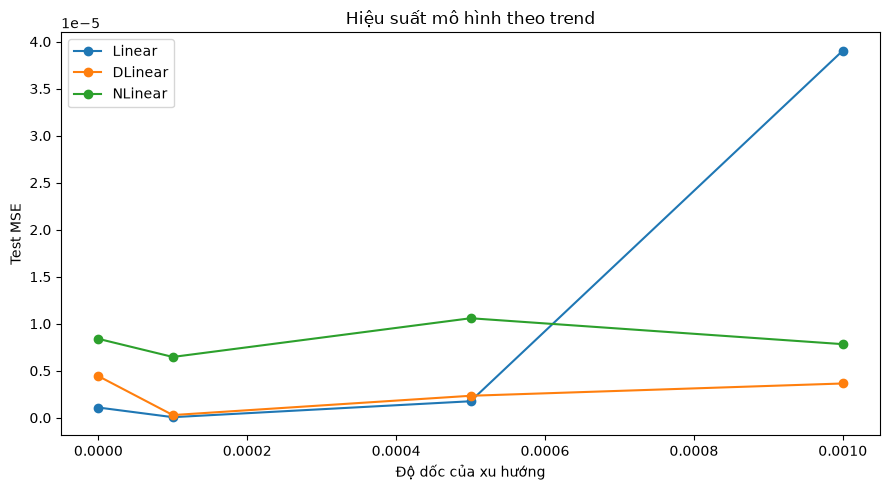

In [78]:
fig, ax = plt.subplots(figsize=(9, 5))

for model_name in models:

    model_data = trend_df[
        trend_df["Model"] == model_name
    ].sort_values("Trend")

    ax.plot(
        model_data["Trend"],
        model_data["MSE"],
        marker="o",
        label=model_name
    )

ax.set_xlabel("Độ dốc của xu hướng")

ax.set_ylabel("Test MSE")

ax.set_title("Hiệu suất mô hình theo trend")

ax.legend()

plt.tight_layout()
plt.show()

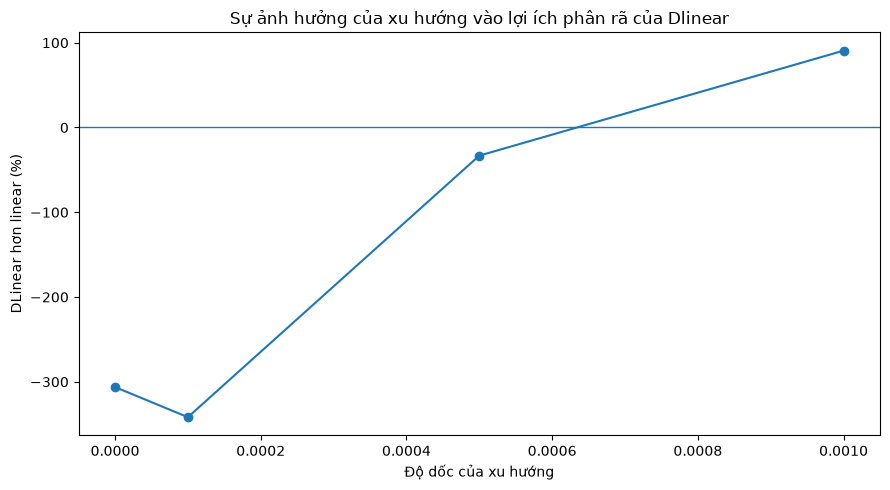

In [79]:
trend_gain_df = (
    trend_mse_table
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    trend_gain_df["Trend"],
    trend_gain_df["DLinear_Gain_%"],
    marker="o"
)

ax.axhline(0, linewidth=1)

ax.set_xlabel("Độ dốc của xu hướng")

ax.set_ylabel("DLinear hơn linear (%)")

ax.set_title("Sự ảnh hưởng của xu hướng vào lợi ích phân rã của Dlinear")

plt.tight_layout()
plt.show()

In [81]:
t, series, trend_true, periodic_true, _ = generate_series(
    length=500,
    period=24,
    amplitude=1.0,
    trend_slope=0.001,
    noise_std=0.0,
    seed=42
)

# lấy ra 1 window
sample = torch.tensor(series[:96], dtype=torch.float32).unsqueeze(0)

# tạo moving average
moving_average = MovingAverage(kernel_size=5)

trend_estimated = moving_average(sample)

seasonal_estimated = (sample - trend_estimated)

# chuyển sang numpy
trend_estimated = (
    trend_estimated
    .squeeze(0)
    .detach()
    .numpy()
)

seasonal_estimated = (
    seasonal_estimated
    .squeeze(0)
    .detach()
    .numpy()
)

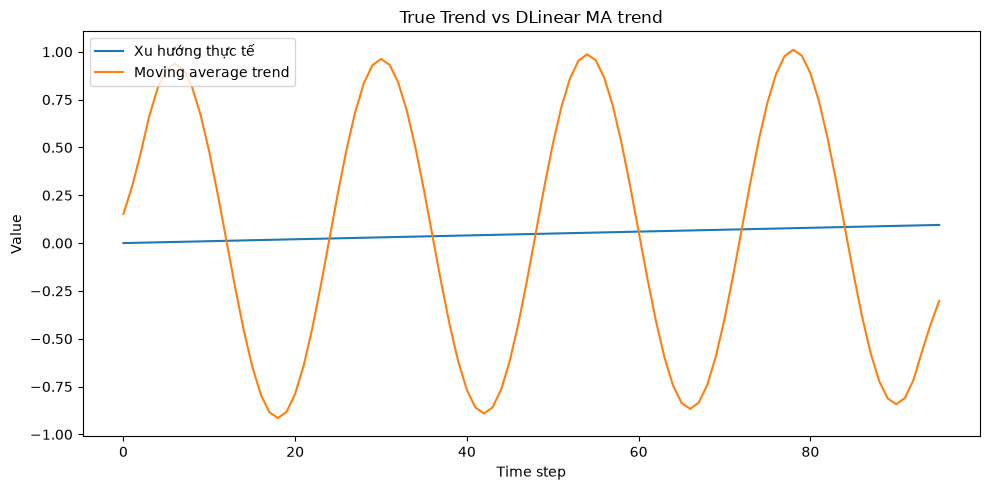

In [82]:
# so sánh truth decomposition với estimated decomposition của Dlinear

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(trend_true[:96], label="Xu hướng thực tế")

ax.plot(trend_estimated, label="Moving average trend")

ax.set_xlabel("Time step")

ax.set_ylabel("Value")

ax.set_title("True Trend vs DLinear MA trend")

ax.legend()

plt.tight_layout()
plt.show()

**Nhận xét:**
Đường trend thực tế có độ dốc nhẹ và đường ước lượng là sóng sin lại có biên độ khá lớn => điều này cho thấy MA của Dlinear đã thất bại trong chuyện triệt tiêu đi sóng chu kì.

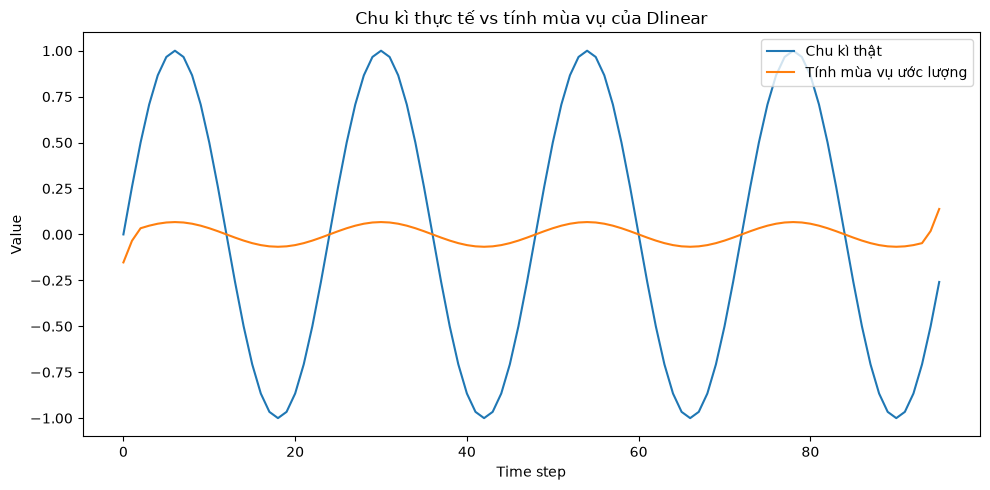

In [83]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(periodic_true[:96], label="Chu kì thật")

ax.plot(seasonal_estimated, label="Tính mùa vụ ước lượng")

ax.set_xlabel("Time step")

ax.set_ylabel("Value")

ax.set_title("Chu kì thực tế vs tính mùa vụ của Dlinear")

ax.legend()

plt.tight_layout()
plt.show()

**Nhận xét:** nhánh seasonal của Dlinear không nhận được tính hiệu chu kỳ chuẩn mà chỉ nhận được phần dư nhiễu rất nhỏ

**Nguyên nhân** có thể đến từ kernel size của MA quá nhỏ so với chu kì P nên nó không đủ rộng để làm phẳng sóng sin => khiến cho MA vô tác dụng

In [84]:
trend_df.to_csv("../results/trend_stress_results.csv", index=False)

trend_mse_table.to_csv("../results/trend_stress_summary.csv")

### Noise stress test

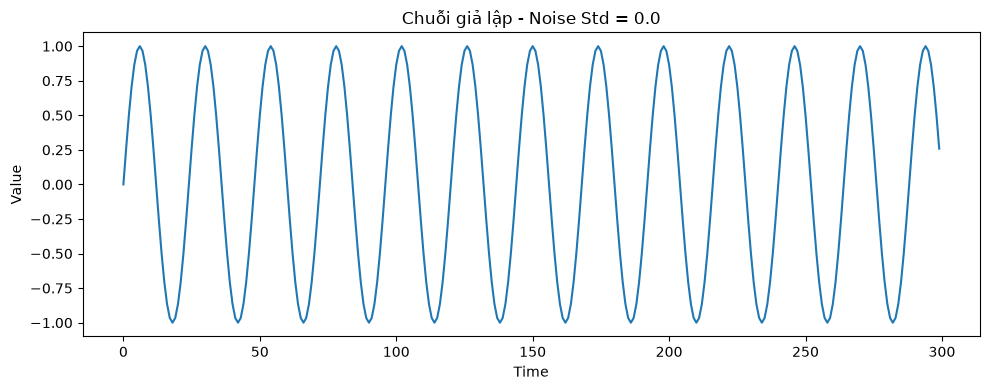

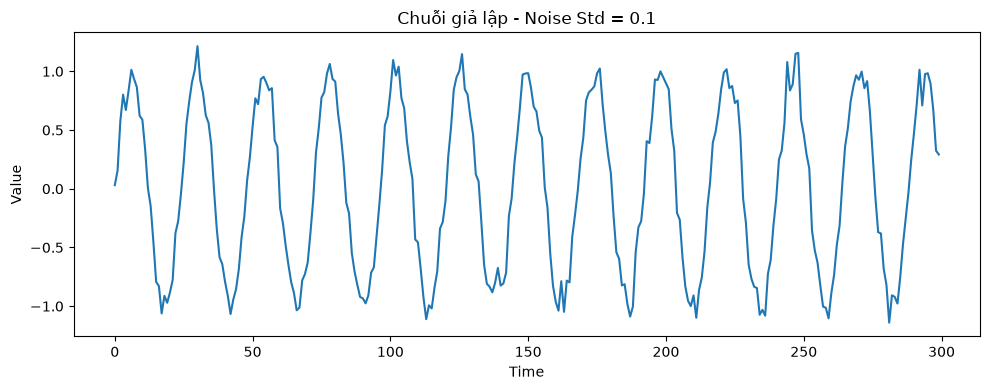

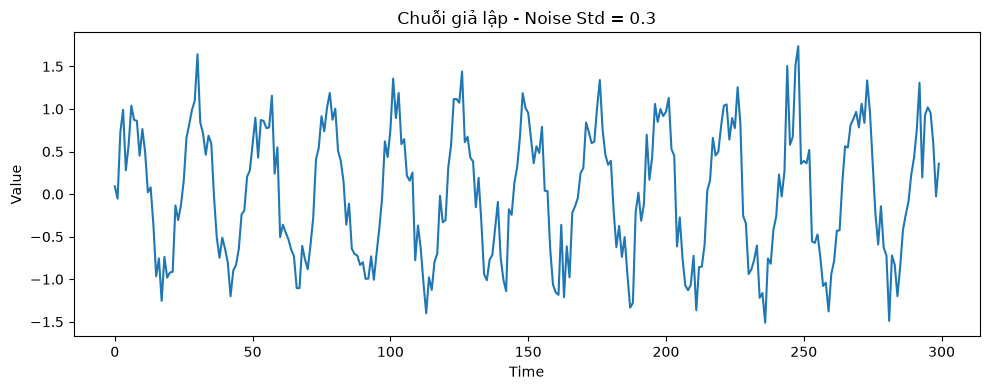

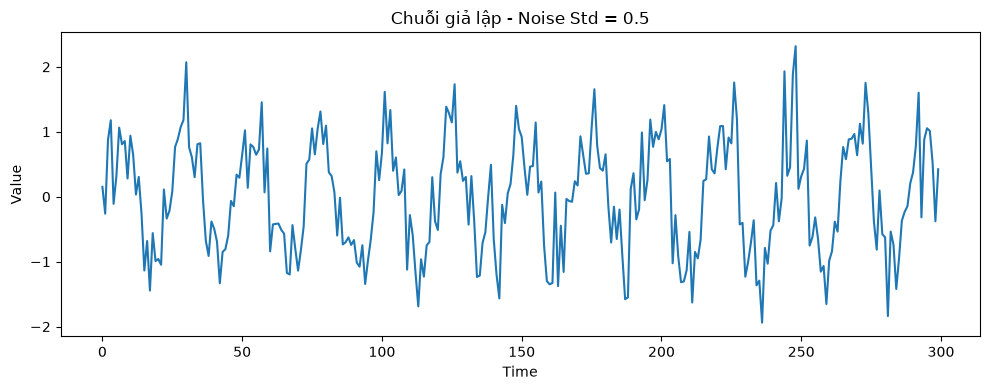

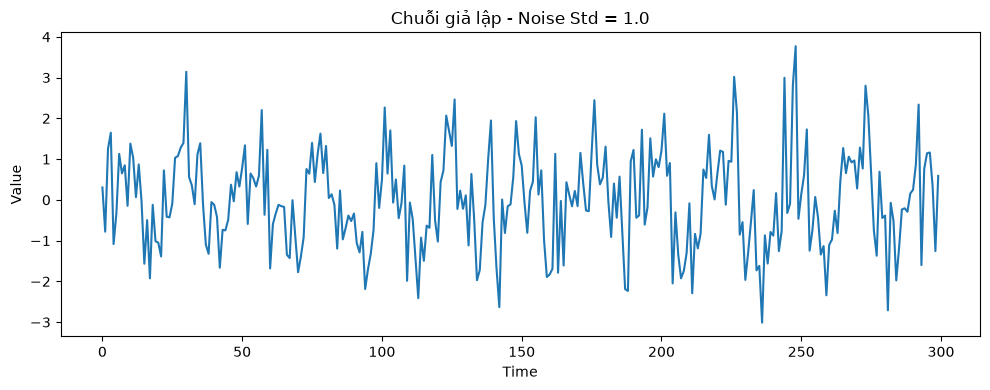

In [85]:
noise_levels = [0.0, 0.1, 0.3, 0.5, 1.0]

for noise_std in noise_levels:

    t, series, trend, periodic, noise = generate_series(
        length=300,
        period=24,
        amplitude=1.0,
        trend_slope=0.0,
        noise_std=noise_std,
        seed=42
    )

    plt.figure(figsize=(10, 4))

    plt.plot(t, series)

    plt.title(f"Chuỗi giả lập - Noise Std = {noise_std}")

    plt.xlabel("Time")
    plt.ylabel("Value")

    plt.tight_layout()
    plt.show()

Noise càng nhiều nhiễu pattern càng mạnh lên

In [ ]:
noise_results = []

models = [
    "Linear",
    "DLinear",
    "NLinear"
]

for noise_std in noise_levels:

    print("\n" + "=" * 60)
    print(
        f"Noise std = {noise_std}"
    )
    print("=" * 60)

    for model_name in models:

        print(
            f"{model_name}"
        )

        result = run_experiment(
            model_name=model_name,
            period=24,
            lookback=96,
            horizon=96,
            amplitude=1.0,
            trend_slope=0.0,
            noise_std=noise_std,
            epochs=50,
            seed=42
        )

        noise_results.append(result)


Noise std = 0.0
Linear
Epoch   1/50 | Train MSE: 0.054465 | Val MSE: 0.000186
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000001
DLinear
Epoch   1/50 | Train MSE: 0.047143 | Val MSE: 0.000112
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000001 | Val MSE: 0.000004
NLinear
Epoch   1/50 | Train MSE: 0.116395 | Val MSE: 0.000315
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000001
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE:

In [87]:
noise_df = pd.DataFrame(noise_results)

noise_df[
    [
        "Model",
        "Noise",
        "L/P",
        "T/P",
        "MSE",
        "MAE"
    ]
]

,Model,Noise,L/P,T/P,MSE,MAE
0,Linear,0.0,4.0,4.0,0.000001,0.000246
1,DLinear,0.0,4.0,4.0,0.000004,0.000522
2,NLinear,0.0,4.0,4.0,0.000008,0.000716
3,Linear,0.1,4.0,4.0,0.011178,0.083178
4,DLinear,0.1,4.0,4.0,0.011109,0.082908
5,NLinear,0.1,4.0,4.0,0.011466,0.084329
6,Linear,0.3,4.0,4.0,0.097666,0.245785
7,DLinear,0.3,4.0,4.0,0.098275,0.246205
8,NLinear,0.3,4.0,4.0,0.099165,0.247900
9,Linear,0.5,4.0,4.0,0.269457,0.407901


In [88]:
noise_mse_table = noise_df.pivot_table(
    index="Noise",
    columns="Model",
    values="MSE"
)

noise_mse_table

Model,DLinear,Linear,NLinear
Noise,,,
0.0,0.000004,0.000001,0.000008
0.1,0.011109,0.011178,0.011466
0.3,0.098275,0.097666,0.099165
0.5,0.270510,0.269457,0.273762
1.0,1.074365,1.072711,1.087997


In [89]:
noise_mse_table["DLinear_Gain_%"] = ((noise_mse_table["Linear"] - noise_mse_table["DLinear"]) / noise_mse_table["Linear"]) * 100

noise_mse_table["Best_Model"] = (
    noise_mse_table[
        [
            "Linear",
            "DLinear",
            "NLinear"
        ]
    ].idxmin(axis=1)
)

noise_mse_table

Model,DLinear,Linear,NLinear,DLinear_Gain_%,Best_Model
Noise,,,,,
0.0,0.000004,0.000001,0.000008,-306.242917,Linear
0.1,0.011109,0.011178,0.011466,0.616328,DLinear
0.3,0.098275,0.097666,0.099165,-0.624345,Linear
0.5,0.270510,0.269457,0.273762,-0.390744,Linear
1.0,1.074365,1.072711,1.087997,-0.154180,Linear


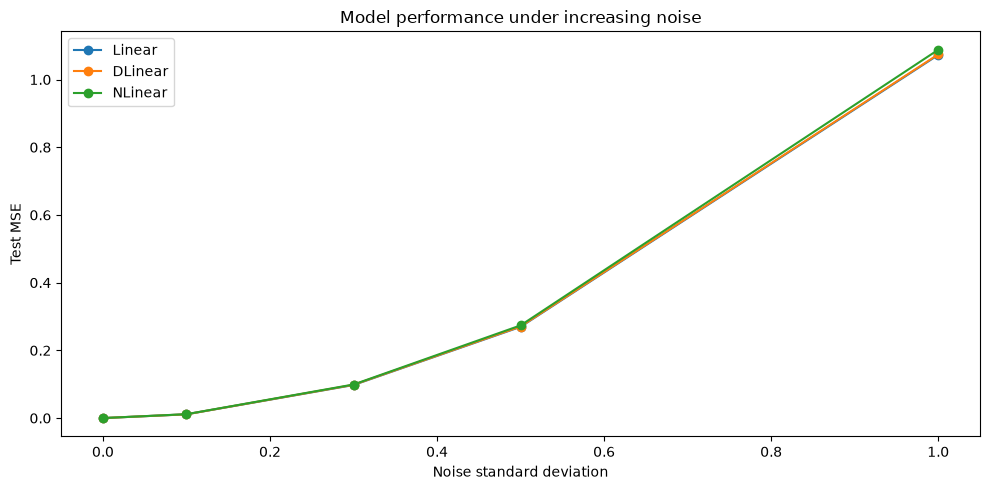

In [90]:
fig, ax = plt.subplots(figsize=(10, 5))

for model_name in models:

    model_data = noise_df[
        noise_df["Model"] == model_name
    ].sort_values("Noise")

    ax.plot(
        model_data["Noise"],
        model_data["MSE"],
        marker="o",
        label=model_name
    )

ax.set_xlabel("Noise standard deviation")

ax.set_ylabel("Test MSE")

ax.set_title("Model performance under increasing noise")

ax.legend()

plt.tight_layout()
plt.show()

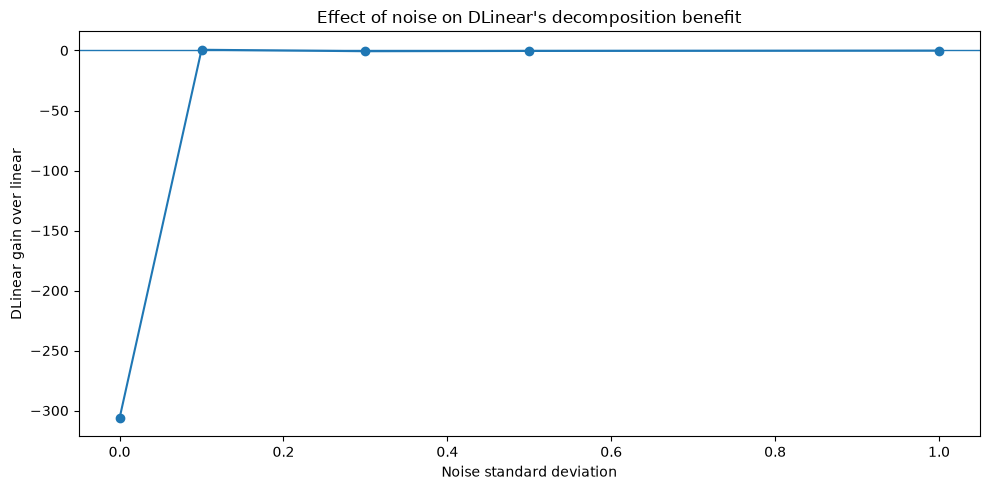

In [92]:
noise_gain_df = (
    noise_mse_table
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    noise_gain_df["Noise"],
    noise_gain_df["DLinear_Gain_%"],
    marker="o"
)

ax.axhline(0, linewidth=1)

ax.set_xlabel("Noise standard deviation")

ax.set_ylabel("DLinear gain over linear")

ax.set_title("Effect of noise on DLinear's decomposition benefit")

plt.tight_layout()
plt.show()

**Nhận xét:** khi không có nhiễu thì linear thuần học tốt. Nhưng khi có nhiễu thì sai số của cả 2 model đều tăng lên đáng kể. Ở đây mức Gain < 0 nên 2 model gần như tương đương nhau.

In [93]:
noise_df.to_csv("../results/noise_stress_results.csv", index=False)

noise_mse_table.to_csv("../results/noise_stress_summary.csv")

In [ ]:
seed_results = []

seeds = [42, 123, 2026]

robustness_configs = [
    (1.0, 1.0), # normal
    (4.0, 4.0), # long forecast
    (0.5, 8.0) # extreme stress case
]

for context_ratio, forecast_ratio in robustness_configs:

    L = int(24 * context_ratio)

    T = int(24 * forecast_ratio)

    for seed in seeds:

        for model_name in models:

            print(
                f"\n"
                f"Model={model_name} | "
                f"L/P={context_ratio} | "
                f"T/P={forecast_ratio} | "
                f"Seed={seed}"
            )

            result = run_experiment(
                model_name=model_name,
                period=24,
                lookback=L,
                horizon=T,
                amplitude=1.0,
                trend_slope=0.0,
                noise_std=0.0,
                epochs=50,
                seed=seed
            )

            seed_results.append(result)


Model=Linear | L/P=1.0 | T/P=1.0 | Seed=42
Epoch   1/50 | Train MSE: 0.259774 | Val MSE: 0.027776
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000000

Model=DLinear | L/P=1.0 | T/P=1.0 | Seed=42
Epoch   1/50 | Train MSE: 0.210502 | Val MSE: 0.018419
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000000 | Val MSE: 0.000000

Model=NLinear | L/P=1.0 | T/P=1.0 | Seed=42
Epoch   1/50 | Train MSE: 0.700704 | Val MSE: 0.139695
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val 

In [96]:
seed_df = pd.DataFrame(seed_results)


In [97]:
seed_summary = (seed_df.groupby(
        [
            "L/P",
            "T/P",
            "Model"
        ]
    )
    .agg(
        MSE_mean=("MSE", "mean"),
        MSE_std=("MSE", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std")
    ).reset_index()
)

seed_summary

,L/P,T/P,Model,MSE_mean,MSE_std,MAE_mean,MAE_std
0,0.5,8.0,DLinear,1.426246e-09,1.402016e-10,0.000029,9.863100e-07
1,0.5,8.0,Linear,1.322234e-09,1.505648e-11,0.000028,2.402862e-07
2,0.5,8.0,NLinear,3.084019e-09,8.461681e-11,0.000042,7.432045e-07
3,1.0,1.0,DLinear,1.263811e-09,3.626286e-11,0.000028,4.504475e-07
4,1.0,1.0,Linear,1.193865e-09,4.137647e-11,0.000027,4.114773e-07
5,1.0,1.0,NLinear,1.569446e-09,1.075513e-10,0.000031,6.331919e-07
6,4.0,4.0,DLinear,2.030483e-06,2.078670e-06,0.000325,1.734310e-04
7,4.0,4.0,Linear,3.888335e-07,6.078955e-07,0.000136,9.603699e-05
8,4.0,4.0,NLinear,3.917417e-06,4.024946e-06,0.000415,2.845479e-04


In [98]:
seed_mse_table = seed_summary.pivot_table(
    index=["L/P", "T/P"],
    columns="Model",
    values="MSE_mean"
)

In [101]:
seed_mse_table["DLinear_Gain_%"] = (
    (
        seed_mse_table["Linear"] - seed_mse_table["DLinear"]
    ) / seed_mse_table["Linear"]
) * 100

seed_mse_table

,Model,DLinear,Linear,NLinear,DLinear_Gain_%
L/P,T/P,,,,
0.5,8.0,1.426246e-09,1.322234e-09,3.084019e-09,-7.866396
1.0,1.0,1.263811e-09,1.193865e-09,1.569446e-09,-5.858787
4.0,4.0,2.030483e-06,3.888335e-07,3.917417e-06,-422.198640


In [102]:
seed_df.to_csv("../results/multi_seed_results.csv", index=False)

seed_summary.to_csv("../results/multi_seed_summary.csv", index=False)

In [103]:
def compute_step_mse(predictions, targets):
    if predictions.shape != targets.shape:
        raise ValueError( "Dự đoán và mục tiêu phải có shape giống nhau")

    step_mse = np.mean((predictions - targets) ** 2, axis=0)

    return step_mse

In [106]:
set_seed(42)

_, series, _, _, _ = generate_series(
    length=5000,
    period=24,
    amplitude=1.0,
    trend_slope=0.0,
    noise_std=0.3,
    seed=42
)

train_loader, val_loader, test_loader = prepare_data(
    series=series,
    lookback=96,
    horizon=96,
    batch_size=32
)

model = DLinear(
    lookback=96,
    horizon=96,
    kernel_size=5
)

train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=50,
    learning_rate=1e-3
)

mse, mae, predictions, targets = evaluate_model(model=model, test_loader=test_loader)

Epoch   1/50 | Train MSE: 0.164929 | Val MSE: 0.104358
Epoch  10/50 | Train MSE: 0.094466 | Val MSE: 0.092344
Epoch  20/50 | Train MSE: 0.094224 | Val MSE: 0.092501
Epoch  30/50 | Train MSE: 0.094112 | Val MSE: 0.092413
Epoch  40/50 | Train MSE: 0.094226 | Val MSE: 0.092461
Epoch  50/50 | Train MSE: 0.094152 | Val MSE: 0.092798


In [107]:
step_mse = compute_step_mse(predictions, targets)

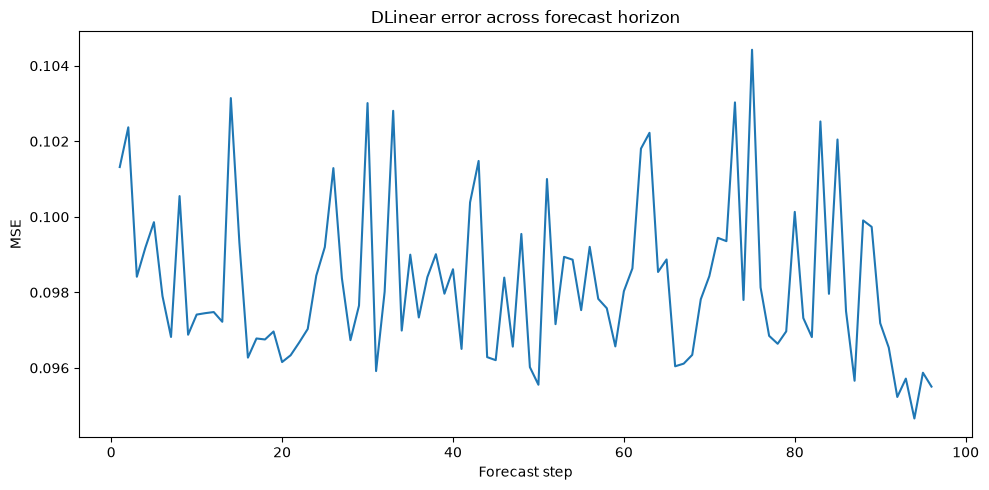

In [108]:
forecast_steps = np.arange(1, len(step_mse) + 1)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(forecast_steps, step_mse)

ax.set_xlabel("Forecast step")

ax.set_ylabel("MSE")

ax.set_title("DLinear error across forecast horizon")

plt.tight_layout()
plt.show()